In [1]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os

DATASET_PATH = "/content/drive/MyDrive/Bone_Fracture_Dataset"

TRAIN_PATH = os.path.join(DATASET_PATH, "train")
VAL_PATH = os.path.join(DATASET_PATH, "val")
TEST_PATH = os.path.join(DATASET_PATH, "test")

print("Train classes :", os.listdir(TRAIN_PATH))
print("Val   classes :", os.listdir(VAL_PATH))
print("Test  classes :", os.listdir(TEST_PATH))

Train classes : ['not fractured', 'fractured']
Val   classes : ['not fractured', 'fractured']
Test  classes : ['fractured', 'not fractured']


In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE   = (128, 128)
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,          # Small rotations (patient positioning)
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,       # Left/right bones can be mirrored
    shear_range=0.1,
    fill_mode='nearest'
)

# Validation & Test — only rescale, NO augmentation
val_test_datagen = ImageDataGenerator(rescale=1./255)

In [5]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',        # Binary: fractured vs not fractured
    color_mode='rgb',
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False
)

class_labels = list(train_generator.class_indices.keys())
print("Class Labels:", class_labels)
print("Class Indices:", train_generator.class_indices)

Found 9247 images belonging to 2 classes.
Found 829 images belonging to 2 classes.
Found 506 images belonging to 2 classes.
Class Labels: ['fractured', 'not fractured']
Class Indices: {'fractured': 0, 'not fractured': 1}


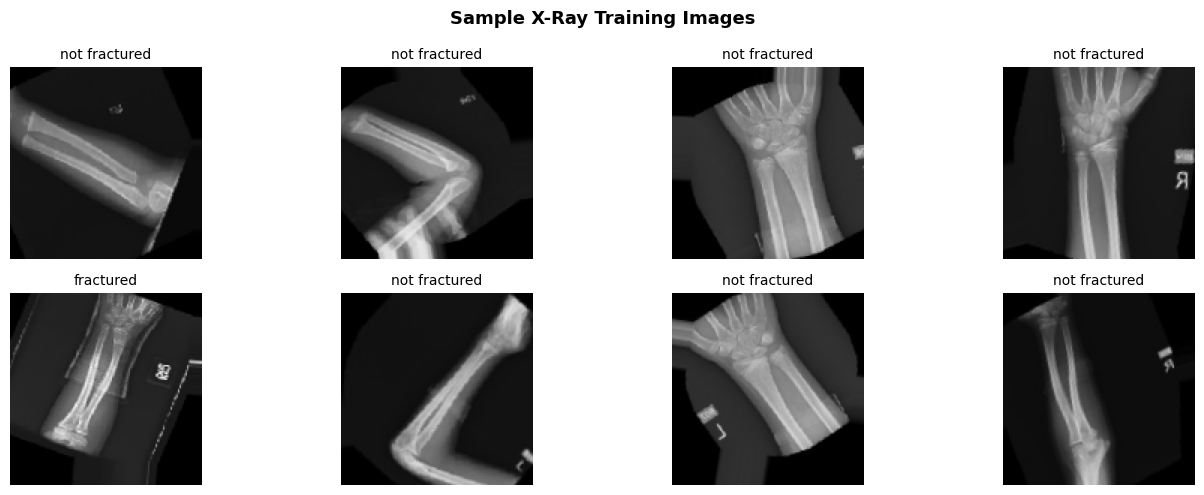

In [6]:
import matplotlib.pyplot as plt

images, labels = next(train_generator)
label_map = {v: k for k, v in train_generator.class_indices.items()}

plt.figure(figsize=(14, 5))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(images[i])
    plt.title(label_map[int(labels[i])], fontsize=10)
    plt.axis('off')
plt.suptitle('Sample X-Ray Training Images', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
from sklearn.utils import class_weight

weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_generator.classes
)
class_weights = {0: weights[0], 1: weights[1]}
print("Class Weights:", class_weights)

Class Weights: {0: np.float64(1.0037993920972645), 1: np.float64(0.9962292609351433)}


In [8]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = False   # Freeze base layers

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')   # Binary output
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,880,065 (56.76 MB)

 Trainable params: 164,865 (644.00 KB)

 Non-trainable params: 14,715,200 (56.13 MB)

In [9]:
early_stop = EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

model.save("/content/drive/MyDrive/bone_fracture_cnn_vgg16.h5")
print("Model saved!")

Epoch 1/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.6024 - loss: 0.7043

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


578/578 ━━━━━━━━━━━━━━━━━━━━ 434s 733ms/step - accuracy: 0.6502 - loss: 0.6378 - val_accuracy: 0.8034 - val_loss: 0.4516 - learning_rate: 1.0000e-04
Epoch 2/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 112s 193ms/step - accuracy: 0.7569 - loss: 0.4974 - val_accuracy: 0.8456 - val_loss: 0.3529 - learning_rate: 1.0000e-04
Epoch 3/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 140s 190ms/step - accuracy: 0.7977 - loss: 0.4305 - val_accuracy: 0.8721 - val_loss: 0.3034 - learning_rate: 1.0000e-04
Epoch 4/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 110s 190ms/step - accuracy: 0.8269 - loss: 0.3788 - val_accuracy: 0.8938 - val_loss: 0.2725 - learning_rate: 1.0000e-04
Epoch 5/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 111s 192ms/step - accuracy: 0.8475 - loss: 0.3450 - val_accuracy: 0.8975 - val_loss: 0.2643 - learning_rate: 1.0000e-04
Epoch 6/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 108s 188ms/step - accuracy: 0.8638 - loss: 0.3139 - val_accuracy: 0.8975 - val_loss: 0.2613 - learning_rate: 1.0000e-04
Epoch 7/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 108s 186ms/

Model saved!


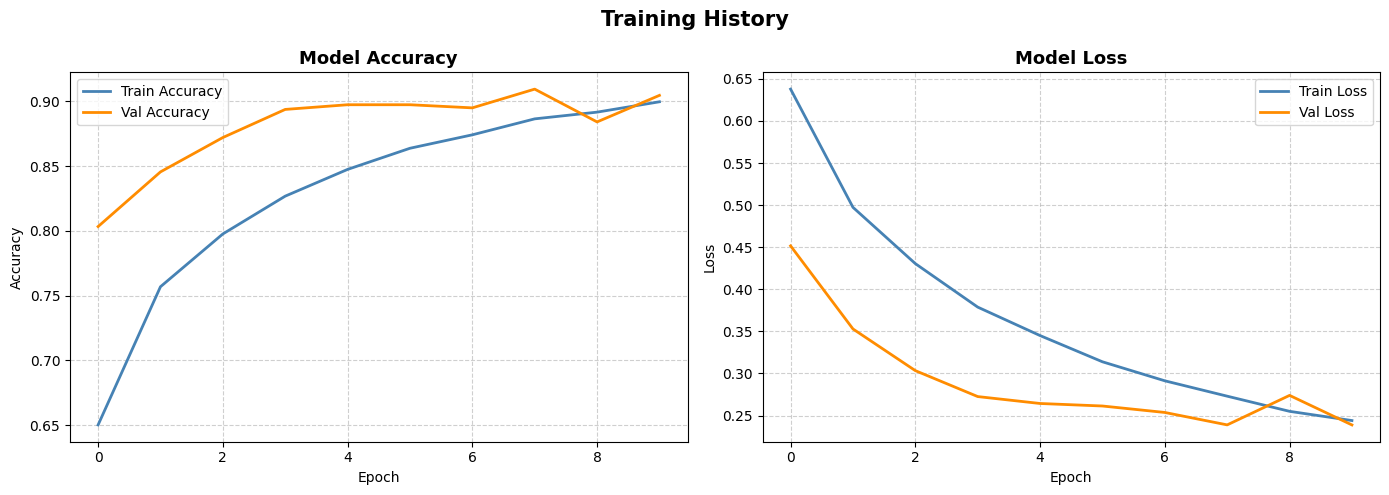

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'],     label='Train Accuracy', color='steelblue',  linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy',   color='darkorange', linewidth=2)
axes[0].set_title('Model Accuracy', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(history.history['loss'],     label='Train Loss', color='steelblue',  linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss',   color='darkorange', linewidth=2)
axes[1].set_title('Model Loss', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Training History', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

In [11]:
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"\nTest Accuracy : {test_accuracy * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")


32/32 ━━━━━━━━━━━━━━━━━━━━ 144s 5s/step - accuracy: 0.8893 - loss: 0.2928

Test Accuracy : 88.93%
Test Loss     : 0.2928


32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 262ms/step


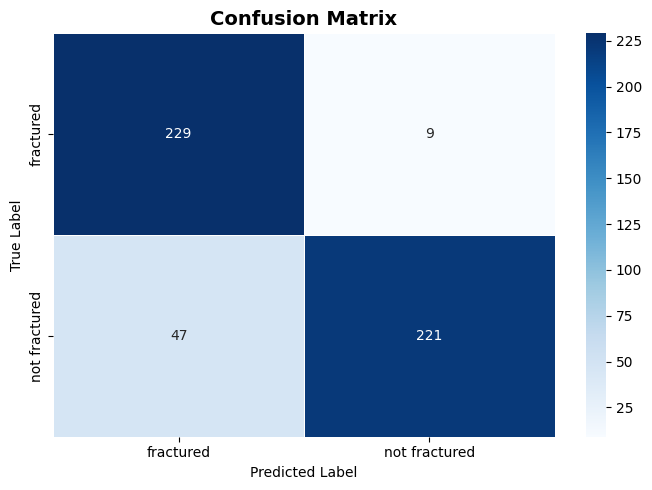


Classification Report:
               precision    recall  f1-score   support

    fractured       0.83      0.96      0.89       238
not fractured       0.96      0.82      0.89       268

     accuracy                           0.89       506
    macro avg       0.90      0.89      0.89       506
 weighted avg       0.90      0.89      0.89       506



In [12]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_generator.reset()
y_pred_probs = model.predict(test_generator, verbose=1)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = test_generator.classes

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels, linewidths=0.5)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True Label'); plt.xlabel('Predicted Label')
plt.tight_layout(); plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels))

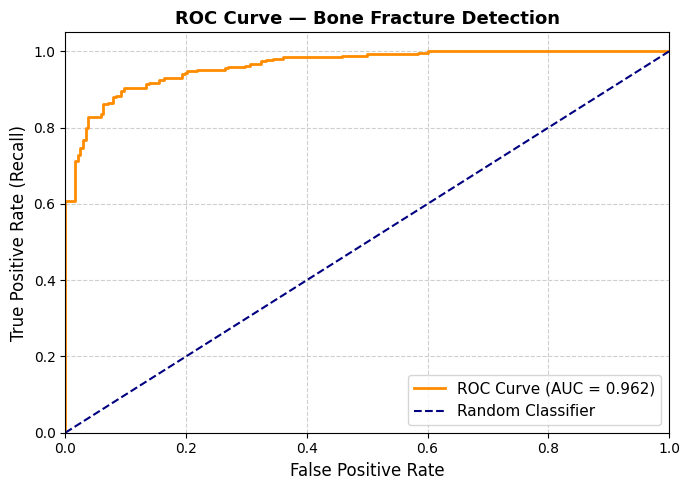

AUC Score: 0.9623


In [13]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', linewidth=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linewidth=1.5, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve — Bone Fracture Detection', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout(); plt.show()

print(f"AUC Score: {roc_auc:.4f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


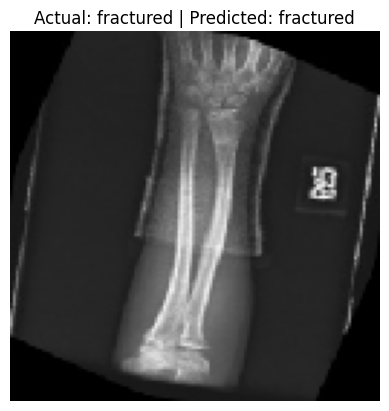

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step


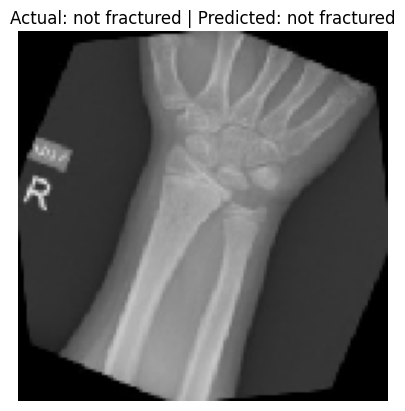

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


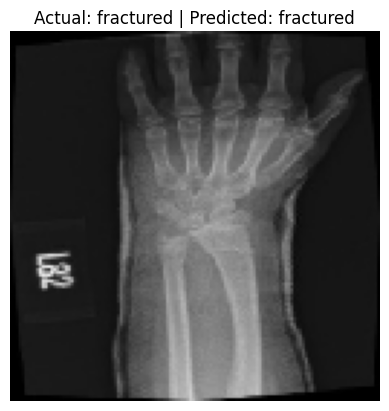

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 359ms/step


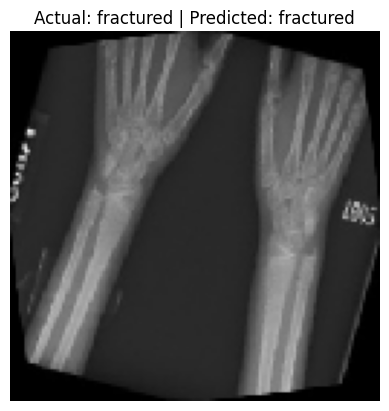

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


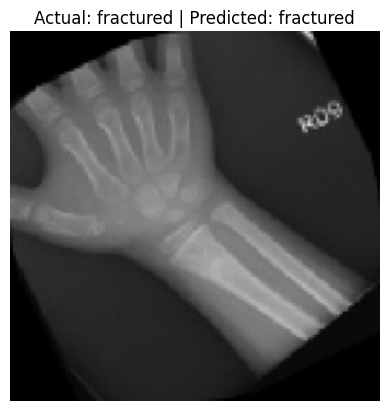

In [15]:
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
import os

# Get class labels
class_labels = list(train_generator.class_indices.keys())

# Function to test random image
def predict_random_image():

    # Pick random class folder
    class_name = random.choice(class_labels)
    class_path = os.path.join(TEST_PATH, class_name)

    # Pick random image
    img_name = random.choice(os.listdir(class_path))
    img_path = os.path.join(class_path, img_name)

    # Load image
    img = image.load_img(img_path, target_size=(128, 128))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    prediction = model.predict(img_array)

    # Convert prediction
    if prediction[0][0] > 0.5:
        pred_label = class_labels[1]
    else:
        pred_label = class_labels[0]

    # Show image
    plt.imshow(img)
    plt.title(f"Actual: {class_name} | Predicted: {pred_label}")
    plt.axis("off")
    plt.show()

# Run multiple times
for _ in range(5):
    predict_random_image()